# Hypothesis Tests and Spark Query Plans

Correlation tests, proportion comparisons, and Spark logical/physical plans, lazy evaluation, grouping, and shuffles.

Originally developed for CSCI 443 at the University of Mississippi. Assignment prompts and provided teaching examples are course material; this notebook contains my submitted responses and code.

Saved outputs are retained from the uploaded coursework. This packaged copy has not been rerun end to end. See the repository README for required data and review notes.


## Part 1 Hypothesis Testing

**Problem 1.1**:

What does a significance level of 0.05 mean in hypothesis testing?  
- A) There is a 5% chance that the null hypothesis is true.  
- B) There is a 95% chance that the null hypothesis is false.  
- C) There is a 5% chance of making a Type I error (rejecting a true null hypothesis).  
- D) There is a 5% chance of making a Type II error (failing to reject a false null hypothesis).

Answer: C


---

**Problem 1.2**: 

Which of the following is true about the relationship between the significance level (alpha) and the probability of a Type I (false positive) error?  
- A) As alpha increases, the probability of a Type I error decreases.  
- B) As alpha increases, the probability of a Type I error increases.
- C) As alpha decreases, the probability of a Type I error increases.  
- D) There is no relationship between alpha and the probability of a Type I error.

Answer: B


---

**Problem 1.3**: 

If a hypothesis test results in a p-value of 0.03 and the chosen significance level is 0.05, what should the researcher conclude?  
- A) Reject the null hypothesis, as the p-value is greater than the significance level.  
- B) Fail to reject the null hypothesis, as the p-value is greater than the significance level.  
- C) Reject the null hypothesis, as the p-value is less than the significance level.  
- D) Fail to reject the null hypothesis, as the p-value is less than the significance level.\

Answer: C


---

**Problem 1.4**: 

What happens when the significance level (alpha) is set too high in a hypothesis test?  
- A) The likelihood of committing a Type II (false negative) error increases.  
- B) The likelihood of committing a Type I (false positive) error decreases.  
- C) The test becomes too stringent, making it harder to reject the null hypothesis.  
- D) The likelihood of committing a Type I (false positive) error increases.

Answer: D


---

**Problem 1.5**: 

Which of the following is true about the p-value in relation to the significance level?  
- A) A p-value greater than the significance level suggests that the null hypothesis should be rejected.  
- B) A p-value smaller than the significance level suggests that the null hypothesis cannot be rejected.  
- C) A p-value smaller than the significance level suggests that the null hypothesis should be rejected.  
- D) The p-value is irrelevant to hypothesis testing and significance level.

Answer: C



## Part 2 Pancakes, Eggs, and Table Heights in the Academy of Lagado

**The Great Breakfast Debate**

During your visit to the flying island of Laputa, you find yourself at the Academy of Lagado— an institution known for its relentless pursuit of impractical science.  Two professors — Professor Eggsworth and Professor Flapjack — are engaged in a heated scientific rivalry.

Each claims to have discovered the secret to determining the ideal breakfast table height for a citizen of Lagado.
  * Professor Eggsworth believes that egg consumption per person predicts optimal table height.
  * Professor Flapjack insists it’s actually the number of pancakes consumed per person that determines how high a Lagadian table should be.

Each professor has gathered data across one hundred households, measuring the average daily consumption of eggs and pancakes, along with the Academy’s recommended breakfast table height (measured in Lagadian cubits).

Their calculating department chair recognizing the danger of standing in the crossfire turns to you, a sacrificable data scientist from Ole Miss, to settle the debate.

**Your Mission**

You are given a dataset `lagado_breakfast_data.csv` with the following columns:
  * eggs_per_person
  * pancakes_per_person
  * ideal_table_height

Your task is to determine:
  1. Which professor’s theory is statistically supported, if either.
  2. Whether the professors should be given tenure or permanently reassigned to the marble pillow division.

**Problem 2.1** Load and visualize the dataset using matplotlib. Create two scatterplots using matplotlib:
 * One of eggs_per_person vs ideal_table_height
 * One of pancakes_per_person vs ideal_table_height
 
Describe any visible trends.

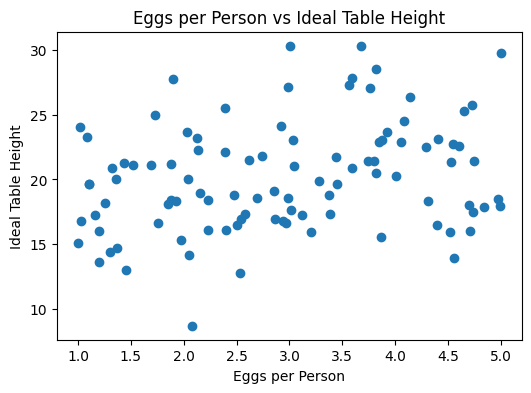

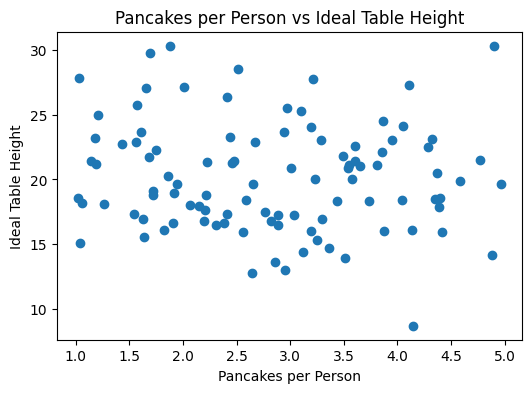

In [0]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('/Volumes/workspace/default/files/lagado_breakfast_data.csv')
df.head()

# Eggs vs table height
plt.figure(figsize=(6,4))
plt.scatter(df['eggs_per_person'], df['ideal_table_height'])
plt.xlabel('Eggs per Person')
plt.ylabel('Ideal Table Height')
plt.title('Eggs per Person vs Ideal Table Height')
plt.show()

# Pancakes vs table height
plt.figure(figsize=(6,4))
plt.scatter(df['pancakes_per_person'], df['ideal_table_height'])
plt.xlabel('Pancakes per Person')
plt.ylabel('Ideal Table Height')
plt.title('Pancakes per Person vs Ideal Table Height')
plt.show()



**Answer**

The scatterplot of eggs per person vs ideal table height shows a slight positive trend, meaning higher egg consumption is somewhat associated with higher table height. However, the relationship is not very strong and the points are somewhat scattered.

The scatterplot of pancakes per person vs ideal table height shows little to no clear trend, and may even suggest a very weak negative relationship. Overall, it appears much more random compared to eggs.

---
**Problem 2.2** For the eggs test and then the pancakes test:

  * State the null and alternative hypotheses for the case where we only want to know whether there is correlation (two-tailed)

**Answer**:
**Eggs vs Table Height**

H₀: ρ = 0  
Hₐ: ρ ≠ 0  

There is no linear correlation between eggs per person and ideal table height under H₀, and Hₐ states that there is a linear correlation.

**Pancakes vs Table Height**

H₀: ρ = 0  
Hₐ: ρ ≠ 0  

There is no linear correlation between pancakes per person and ideal table height under H₀, and Hₐ states that there is a linear correlation.


---
**Problem 2.3**  Compute the Pearson correlation coefficient and associated p-value for each relationship:
 * Eggs vs Table Height
 * Pancakes vs Table Height
Report both r-values and p-values.

In [0]:
# ANSWER HERE

from scipy.stats import pearsonr

# Eggs vs table height
r_eggs, p_eggs = pearsonr(df['eggs_per_person'], df['ideal_table_height'])

# Pancakes vs table height
r_pancakes, p_pancakes = pearsonr(df['pancakes_per_person'], df['ideal_table_height'])

print("Eggs vs Table Height:")
print("r =", r_eggs)
print("p =", p_eggs)

print("\nPancakes vs Table Height:")
print("r =", r_pancakes)
print("p =", p_pancakes)




Eggs vs Table Height:
r = 0.2637117057448766
p = 0.008023854284992693

Pancakes vs Table Height:
r = -0.09336653610371434
p = 0.35551381302619944


---
**Problem 2.4** Determine whether the results are statistically significant at the α = 0.01 level.
 * Interpret the result in plain language. (Which professor, if any, is right?)

**Answer**

Eggs: p = 0.008 < 0.01 → statistically significant
Pancakes: p = 0.356 > 0.01 → not significant

At the 0.01 significance level, egg consumption shows a statistically significant relationship with ideal table height, while pancake consumption does not. This suggests that Professor Eggsworth’s theory is supported by the data, although the relationship is relatively weak. Professor Flapjack’s theory is not supported.

##### ---
**Problem 2.5** Restate the null and alternative hypotheses for the egg test and then the pancake test for the case where we are trying to determine whether there is statistically significant evidence of a positive correlation (one-tailed).  

Explain the difference between one and two tailed tests.

**Answer**: 
**Eggs vs Table Height (One-Tailed)**

H₀: ρ ≤ 0  
Hₐ: ρ > 0  

**Pancakes vs Table Height (One-Tailed)**

H₀: ρ ≤ 0  
Hₐ: ρ > 0  

Difference between one-tailed and two-tailed tests:  
A two-tailed test checks for any relationship (positive or negative), while a one-tailed test checks for a relationship in a specific direction (positive only). One-tailed tests are more focused but must be justified beforehand.


---
**Problem 2.6** Compute the associated p-values for the given data under the given null hypotheses from Problem 2.5:
 * Eggs vs Table Height
 * Pancakes vs Table Height
Report both p-values.

In [0]:
# ANSWER HERE

# One-tailed p-values for positive correlation
if r_eggs > 0:
    p_eggs_one = p_eggs / 2
else:
    p_eggs_one = 1 - (p_eggs / 2)

if r_pancakes > 0:
    p_pancakes_one = p_pancakes / 2
else:
    p_pancakes_one = 1 - (p_pancakes / 2)

print("One-tailed p-value for eggs:", p_eggs_one)
print("One-tailed p-value for pancakes:", p_pancakes_one)

One-tailed p-value for eggs: 0.0040119271424963465
One-tailed p-value for pancakes: 0.8222430934869003


---
**Problem 2.7** Determine whether the tests described in Problem 2.5 and computed in Problem 2.6 are statistically significant at the α = 0.01 level.
 * Interpret the result in plain language.

**Answer**
Significance level: α = 0.01  

Eggs:  
p = 0.0040 < 0.01 → Reject H₀  

Pancakes:  
p = 0.8222 > 0.01 → Fail to reject H₀  

Interpretation:  
There is statistically significant evidence of a positive correlation between egg consumption and ideal table height. There is no statistically significant evidence of a positive correlation for pancakes. Therefore, Professor Eggsworth is supported, while Professor Flapjack is not.

---
**Problem 2.8** (optional!) The Lagadian government is considering funding a research grant to produce adjustable-height tables based on breakfast habits. Would you recommend this investment based on the evidence obtained so far? Support your recommendation with humor and statistics.

**Answer** 
Based on the statistical results, I would not recommend funding adjustable-height tables based on pancake consumption, since there is no evidence supporting that relationship. Egg consumption does show a statistically significant relationship with table height, but the correlation is relatively weak, so further research would be needed before making major investments. If funding must be allocated, it should go toward egg-based research, while the pancake-based theory is not currently justified.

## Part 3. A Lilliputian Statistical Crisis

For centuries, the proud nation of Lilliput has enforced the imperial edict that boiled eggs must be opened at the small end — a decree that led to the exile of the rebellious Big-Endians to the neighboring island of Blefuscu. This seemingly trivial matter has caused six rebellions, countless beheadings, and at least one naval war.

Recently, the Ministry of Tradition commissioned a poll to reinforce the cultural superiority of the Little-End way. Citizens of Lilliput and Blefuscu were asked privately which end they preferred to crack their eggs. The results shocked the establishment:
  * 52 out of 100 Lilliputians said they preferred the big end.
  * 36 out of 80 Blefuscudians said they preferred the big end.

Panic ensued. The High Chamber of Truthiness demanded a rigorous statistical analysis before launching another inquisition or rewriting the sacred breakfast scriptures.

**Your Mission:**

* Restore Order (or Confirm Chaos)

* Protect your head.

---
**Problem 3.1**.  State the null hypothesis and alternative hypothesis to test whether the two populations (Lilliput and Blefuscu) significantly differ in their proportions of big-end preference.

**Answer**
Let p₁ be the true proportion of Lilliputians who prefer the big end, and let p₂ be the true proportion of Blefuscudians who prefer the big end.

H₀: p₁ = p₂  
Hₐ: p₁ ≠ p₂  

The null hypothesis states that the two populations do not differ in their proportions of big-end preference. The alternative hypothesis states that the two populations do differ.

---
**Problem 3.2**. Calculate the sample proportions for each group. Which group appears to be more big-endian? Which group is supposed to be?

**Answer**
The sample proportion for Lilliput is

p̂₁ = 52 / 100 = 0.52

The sample proportion for Blefuscu is

p̂₂ = 36 / 80 = 0.45

This means that 52% of Lilliputians in the sample preferred the big end, while 45% of Blefuscudians in the sample preferred the big end.

Based on the sample, Lilliput appears to be more big-endian. Ironically, Lilliput is the group that is supposed to support the little-end tradition.

---
**Problem 3.3**. Under the null hypothesis stated in Problem 20, calculate the pooled estimate of the proportion and the standard error. 

**Answer**
Under the null hypothesis, we use the pooled sample proportion:

p̂ = (x₁ + x₂) / (n₁ + n₂)

Substituting the values:

p̂ = (52 + 36) / (100 + 80) = 88 / 180 = 0.4889

The standard error is

SE = sqrt( p̂(1 - p̂)(1/n₁ + 1/n₂) )

Substituting the values:

SE = sqrt(0.4889(1 - 0.4889)(1/100 + 1/80))

SE = sqrt((0.4889)(0.5111)(0.0225))

SE ≈ sqrt(0.005624)

SE ≈ 0.0750

---
**Problem 3.4** Assume that the sampling distribution of the sample
proportion is reasonably approximated by a normal (Gaussian) distribution.
Then compute the z-score and corresponding p-value for the difference in sample
proportions. Show the steps.

In [0]:
# HERE

from IPython.display import Markdown, display
import math
from scipy.stats import norm

p1_hat = 52/100
p2_hat = 36/80
p_pool = (52 + 36) / (100 + 80)
SE = math.sqrt(p_pool * (1 - p_pool) * (1/100 + 1/80))
Z_D = (p1_hat - p2_hat) / SE

display(Markdown(f"Z = {Z_D:.3f}"))

p_value = 2 * (1 - norm.cdf(abs(Z_D)))
display(Markdown(f"p-value = {p_value:.3f}"))

Z = 0.934

p-value = 0.351

**Answer** Let $D$ denote the difference between the sample proportions for Lilliputions $p_L$ and
Blefuscudians $p_B$.  

The Z-score of a sample of the sample proportion $D$ is thus given by

Z = (p̂₁ - p̂₂) / sqrt( p̂(1 - p̂)(1/n₁ + 1/n₂) )

where p̂ is the pooled sample proportion under the null hypothesis.

Using the values from above,

Z = (0.52 - 0.45) / sqrt(0.4889(1 - 0.4889)(1/100 + 1/80))
≈ 0.933

In [0]:
from IPython.display import Markdown, display

Z_D = (p1_hat - p2_hat) / SE
display(Markdown(f"$Z_D$ = {Z_D}"))


$Z_D$ = 0.933563871396213

Let $\Phi$ denote the CDF of the Gaussian distribution.
Thus the p-value is given by

p-value = 2P(Z > |0.933|)

Using the standard normal distribution,

p-value ≈ 2(1 - Φ(0.933)) ≈ 0.351

Therefore, the p-value is approximately 0.351.

**Problem 3.5**. At a 5% significance level, can the High Chamber reject the null hypothesis and declare a statistically meaningful betrayal of Lilliputian values? Justify your answer.

**Answer** 
At the 5% significance level, we compare the p-value to α = 0.05.

Since

p-value ≈ 0.351 > 0.05,

we fail to reject H₀.

This means there is not enough statistical evidence to conclude that the two populations differ in their proportions of big-end preference. So, the High Chamber cannot reject the null hypothesis and cannot claim a statistically meaningful betrayal of Lilliputian values based on this sample.

## Part 4. Spark

Little is known about the later travels of Gulliver, but he once remarked that he narrowly evaded an untimely death by missing the departure of the Titanic. Many of his friends were not so fortunate. In his later years, he devoted himself to studying the records of that ill-fated voyage, seeking to understand the patterns and structure hidden within the data.

In this assignment, you will follow in Gulliver’s footsteps, using Spark to analyze the Titanic dataset.  (Forgive the narrative jump)

Let's start by just trying to understand the data.  This is called exploratory data analysis.

---
**Problem 4.1.**

We have worked with this dataset before, but we have not yet looked beneath the hood.

a) How many passengers are there? Show the code used to answer this question. This part is straightforward, but part (b) is not.

In [0]:
df = spark.read.csv(
    "/Volumes/workspace/default/files/train.csv",
    header=True,
    inferSchema=True
)

df.printSchema()
df.show(5)

root
 |-- PassengerId: integer (nullable = true)
 |-- Survived: integer (nullable = true)
 |-- Pclass: integer (nullable = true)
 |-- Name: string (nullable = true)
 |-- Sex: string (nullable = true)
 |-- Age: double (nullable = true)
 |-- SibSp: integer (nullable = true)
 |-- Parch: integer (nullable = true)
 |-- Ticket: string (nullable = true)
 |-- Fare: double (nullable = true)
 |-- Cabin: string (nullable = true)
 |-- Embarked: string (nullable = true)

+-----------+--------+------+--------------------+------+----+-----+-----+----------------+-------+-----+--------+
|PassengerId|Survived|Pclass|                Name|   Sex| Age|SibSp|Parch|          Ticket|   Fare|Cabin|Embarked|
+-----------+--------+------+--------------------+------+----+-----+-----+----------------+-------+-----+--------+
|          1|       0|     3|Braund, Mr. Owen ...|  male|22.0|    1|    0|       A/5 21171|   7.25| NULL|       S|
|          2|       1|     1|Cumings, Mrs. Joh...|female|38.0|    1|    0|   

In [0]:
df.count()

891

**Answer** 891 passengers

b) On the DataFrame, run:

```python
df.explain(extended=True)
```

In [0]:
df.explain(extended=True)

== Parsed Logical Plan ==
Relation [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] csv

== Analyzed Logical Plan ==
PassengerId: int, Survived: int, Pclass: int, Name: string, Sex: string, Age: double, SibSp: int, Parch: int, Ticket: string, Fare: double, Cabin: string, Embarked: string
Relation [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] csv

== Optimized Logical Plan ==
Relation [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] csv

== Physical Plan ==
FileScan csv [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] Batched: false, DataFilters: [], Format: CSV, Location

Show the result here.

**Answer** 

Describe each plan. What are the roles of the parsed logical plan, analyzed logical plan, optimized logical plan, and physical plan? How does each plan differ from the one before it?  What is a 'Relation'?  

This is a somewhat degenerate example because there are no obvious transformations in the plan. Although count() is an action, the DataFrame still retains its logical plan after the action has executed, so explain() can still be used to inspect it.

**Answer** 
The parsed logical plan is Spark’s initial internal representation of the query. It reflects the structure of the DataFrame before Spark has fully resolved all column names and data types.

The analyzed logical plan is the parsed plan after Spark has checked the schema and resolved all references. At this stage, Spark confirms that the columns and relation actually exist and assigns internal identifiers and types.

The optimized logical plan is the analyzed plan after Spark applies optimization rules. Spark may simplify the plan, remove unnecessary steps, and prepare the query to run more efficiently.

The physical plan is the concrete execution strategy Spark chooses. It shows the actual operators Spark will use to process the data.

Each plan builds on the one before it. The parsed logical plan shows the original structure, the analyzed logical plan resolves meaning, the optimized logical plan improves efficiency, and the physical plan shows execution details.

A Relation refers to the underlying data source being read. In this case, it is the Titanic dataset loaded from the CSV file train.csv.

This example is somewhat simple because there are no obvious transformations. Even though count() is an action, the DataFrame still retains its logical plan, so explain() can still be used afterward.

c) This plan is being examined in a serverless version of Spark. How would the situation differ if we were running Spark on a cluster with separate hosts (or virtual machines) for the driver and the executors?

**Answer** In a cluster with separate hosts or virtual machines, the driver would build the logical and physical plans and coordinate execution, while the executors on other machines would perform the actual data processing tasks. Communication between the driver and executors would happen over the network, so task scheduling and data movement would be more visible and could introduce extra overhead. In a serverless Spark environment, much of this infrastructure is abstracted away and managed automatically.

---
**Problem 4.2**

Let us now try something slightly more complicated. The previous problem involved only an action. Now we introduce a narrow transformation.

a) Selecting `"Age"` can be written as:

```python
df2 = df.select("Age")
```
What is df2? How does it differ from `df`?

In [0]:
df2 = df.select("Age")

**Answer** df2 is a new Spark DataFrame that contains only the Age column from the original DataFrame df. It differs from df because df contains all columns from train.csv, while df2 contains just one column. Spark DataFrames are immutable, so df2 does not modify df; it creates a new DataFrame with its own logical plan.

b) Run explain(extended=True) on both `df` and `df2`, showing the operation and result below. How are the plans different? Why?

In [0]:
df.explain(extended=True)
df2.explain(extended=True)

== Parsed Logical Plan ==
Relation [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] csv

== Analyzed Logical Plan ==
PassengerId: int, Survived: int, Pclass: int, Name: string, Sex: string, Age: double, SibSp: int, Parch: int, Ticket: string, Fare: double, Cabin: string, Embarked: string
Relation [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] csv

== Optimized Logical Plan ==
Relation [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] csv

== Physical Plan ==
FileScan csv [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] Batched: false, DataFilters: [], Format: CSV, Location

**Answer** The plan for df2 includes a Project node, while the plan for df is simply reading the full relation. The Project node appears because df2 selects only the Age column. This changes the plan by adding a column-selection step. Spark includes this because it needs to produce a DataFrame with only the requested column.

c) Compare the explain output for `df2` with the `explain(extended=True)` output you examined in Problem 4.1. What is Project?

**Answer** Project is the logical operator that represents selecting certain columns from a DataFrame. In this case, it tells Spark to keep only the Age column. It appears in the plan for df2 because df2 is the result of df.select("Age").

d) What was sent from the driver to executors when you ran:

```
df2 = df.select("Age")
```

It is a bit of a trick question.  Why?  Explain.

**Answer** Nothing was actually sent to the executors yet. This is a trick question because Spark uses lazy evaluation. The statement df2 = df.select("Age") only defines a transformation and creates a new logical plan. Spark does not execute anything until an action such as show(), count(), or collect() is called.

---
**Problem 4.3**

Let us now introduce a somewhat more complex plan.

Consider:

```python
from pyspark.sql.functions import col

df3 = df.select("Age", "Fare").filter(col("Age") < 12)
```

a) Before running explain, predict what nodes you expect to appear in the logical plan.

In [0]:
from pyspark.sql.functions import col

df3 = df.select("Age", "Fare").filter(col("Age") < 12)

**Answer** I would expect the logical plan to contain a Relation node for the CSV data source, a Project node to select the Age and Fare columns, and a Filter node to keep only rows where Age < 12.

b) Run df3.explain(extended=True) below.
How does the parsed logical plan differ from the analyzed logical plan?

In [0]:
df3.explain(extended=True)

== Parsed Logical Plan ==
'Filter '`<`('Age, 12)
+- 'Project ['Age, 'Fare]
   +- Relation [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] csv

== Analyzed Logical Plan ==
Age: double, Fare: double
Filter (Age#10972 < cast(12 as double))
+- Project [Age#10972, Fare#10976]
   +- Relation [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] csv

== Optimized Logical Plan ==
Project [Age#10972, Fare#10976]
+- Filter (isnotnull(Age#10972) AND (Age#10972 < 12.0))
   +- Relation [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] csv

== Physical Plan ==
PhotonResultStage
+- PhotonColumnarToRow
   +- PhotonFilter (isnotnull(Age#10972) AND (Age#10972 < 12.0))
      +- PhotonRowToColumnar
  

**Answer** The parsed logical plan shows the query structure in a more raw form. The analyzed logical plan resolves the column names Age and Fare against the schema in train.csv, confirms they exist, and assigns them data types and internal identifiers. So the analyzed plan is more explicit and fully resolved.

c) What does the Filter node represent?

**Answer** The Filter node represents the condition Age < 12. It tells Spark to keep only the rows where the passenger’s age is less than 12 and discard the rest.

d) Why is this still a narrow transformation?

**Answer** This is still a narrow transformation because each output row depends only on data from a single input partition. Spark does not need to move rows between partitions to perform a column selection and row filter. Each partition can be processed independently.

e) In what order should the plan be read?

**Answer** The plan should generally be read from the bottom up. The bottom shows the data source being read, and each node above it represents another transformation applied to that data.

f) Did the order of operations change between the analyzed logical plan and 
the optimized logical plan?  Why might Spark do this?

**Answer** Yes, the order may change. Spark may push the Filter lower in the plan so that it removes unnecessary rows as early as possible. Spark does this as an optimization to reduce the amount of data processed in later steps and improve performance.

g) In the physical plan, does Spark read all columns from the CSV file? How can you tell?

**Answer** Since the data source is a CSV file, Spark may still need to read each row from the file, but in the execution plan it only uses the columns required for the query, which are Age and Fare. You can tell by looking at the scan or project-related parts of the physical plan. If only Age and Fare appear there, that shows Spark is logically pruning unnecessary columns for the query.

---
**Problem 4.4**

Now let's introduce `groupBy`.

Consider:

```python
  df4 = df.groupBy("Pclass").count()
```

a) What is the type of `df4`? 

In [0]:
df4 = df.groupBy("Pclass").count()

**Answer** df4 is a Spark DataFrame. It represents the grouped result, with one row for each passenger class and a count for each class.

b) The function `count()` was previously used as an action (e.g., `df.count()`).
Why does `count()` here return a different type?

**Answer** Earlier, count() was used directly on a DataFrame, so it acted as an action and returned a single Python integer representing the total number of rows. Here, count() is being called after groupBy("Pclass"), so it is being applied to a GroupedData object. In this case, count() is an aggregation that returns a new DataFrame containing one count per group.

c) Does this line of code trigger execution? Why or why not?

**Answer** No, this line does not trigger execution. Spark still uses lazy evaluation. The line defines a grouped aggregation and creates a logical plan, but Spark will not execute it until an action such as show(), collect(), or display() is called.

d) Before running explain, predict what nodes you expect to appear in the logical plan.

**Answer** I would expect the logical plan to include a Relation node for the Titanic CSV file, an Aggregate node representing the grouping by Pclass and counting rows, and possibly a Project node depending on how Spark represents the grouped output internally.

e) Run 

```python
  df4.explain(extended=true)
```

What new node(s) appear in the logical plan that did not appear in the previous examples?
Why?

In [0]:
df4.explain(extended=True)

== Parsed Logical Plan ==
'Aggregate ['Pclass], ['Pclass, 'count(1) AS count#11044]
+- Relation [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] csv

== Analyzed Logical Plan ==
Pclass: int, count: bigint
Aggregate [Pclass#10969], [Pclass#10969, count(1) AS count#11044L]
+- Relation [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] csv

== Optimized Logical Plan ==
Aggregate [Pclass#10969], [Pclass#10969, count(1) AS count#11044L]
+- Project [Pclass#10969]
   +- Relation [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] csv

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- == Initial Plan ==
   PhotonResultStage
   +- PhotonColumnarToRow
      +- PhotonGroupingAgg(limi

**Answer** The main new node is Aggregate. This appears because Spark now has to group rows by Pclass and compute the count for each group. In the physical plan, you may also see nodes such as HashAggregate and Exchange. HashAggregate performs the grouped computation, and Exchange indicates a shuffle that may be needed to bring rows with the same Pclass together.

f) Run `display(df4.collect())` below.  What happened?  What is `collect`?  Explain.

In [0]:
display(df4.collect())

[Row(Pclass=3, count=491), Row(Pclass=1, count=216), Row(Pclass=2, count=184)]

**Answer** When this runs, Spark executes the query, computes the grouped counts, and returns all the rows of the result to the driver as a local Python list of Row objects. The collect() function is an action that gathers the entire result into the driver’s memory. Then display() shows those collected rows in tabular form in Databricks.

The result should show one row for each value of Pclass with its corresponding count. Since the Titanic training dataset has passenger classes 1, 2, and 3, the result will have three rows.

---
**Problem 4.5**

Let us now consider a more complex query involving multiple stages of computation and a shuffle.

Consider:

```python
from pyspark.sql.functions import avg

df5 = df.groupBy("Pclass").agg(avg("Fare").alias("avg_fare")).orderBy("avg_fare", ascending=False)
```

a) What is the type of df5? Does this line of code trigger execution?

In [0]:
from pyspark.sql.functions import avg

df5 = df.groupBy("Pclass").agg(avg("Fare").alias("avg_fare")).orderBy("avg_fare", ascending=False)

**Answer** df5 is a Spark DataFrame. This line does not trigger execution because it only defines transformations: grouping, aggregation, and sorting. Spark will wait until an action is called before actually running the computation.

b) Before running explain, predict the logical operations that should appear in the plan.

**Answer** I would expect the plan to contain a Relation node for the Titanic CSV file, an Aggregate node to group by Pclass and compute avg(Fare), and a Sort node to order the results by avg_fare in descending order. A Project node may also appear because the aggregated column is being aliased as avg_fare.

c) Run:

```python
  df5.explain(extended=True)
```

Put the ouput here and descibe the role of each node.

In [0]:
df5.explain(extended=True)

== Parsed Logical Plan ==
'Sort ['avg_fare DESC NULLS LAST], true
+- 'Aggregate ['Pclass], ['Pclass, 'avg('Fare) AS avg_fare#11056]
   +- Relation [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] csv

== Analyzed Logical Plan ==
Pclass: int, avg_fare: double
Sort [avg_fare#11056 DESC NULLS LAST], true
+- Aggregate [Pclass#10969], [Pclass#10969, avg(Fare#10976) AS avg_fare#11056]
   +- Relation [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Cabin#10977,Embarked#10978] csv

== Optimized Logical Plan ==
Sort [avg_fare#11056 DESC NULLS LAST], true
+- Aggregate [Pclass#10969], [Pclass#10969, avg(Fare#10976) AS avg_fare#11056]
   +- Project [Pclass#10969, Fare#10976]
      +- Relation [PassengerId#10967,Survived#10968,Pclass#10969,Name#10970,Sex#10971,Age#10972,SibSp#10973,Parch#10974,Ticket#10975,Fare#10976,Ca

**Answer** The Relation node represents reading the Titanic data from train.csv.

The Aggregate node groups rows by Pclass and computes the average of the Fare column.

The Project node may appear to represent the aliasing of the aggregate result as avg_fare.

The Sort node orders the grouped results by avg_fare in descending order.

In the physical plan, nodes such as HashAggregate, Exchange, and Sort are common. HashAggregate performs aggregation, Exchange indicates data reshuffling across partitions, and Sort performs the ordering.

d) In the physical plan, locate all occurrences of Exchange.
 * How many are there?
 * What operation(s) require a shuffle?

**Answer** There are often two Exchange nodes in this query, although the exact number can vary depending on the Spark version and execution strategy.

One shuffle is required for the groupBy, because rows with the same Pclass may be distributed across multiple partitions and must be brought together.

Another shuffle is often required for the orderBy, because sorting by avg_fare requires a global ordering across partitions.

e) Why does computing the average fare by `Pclass` require data to move across partitions?

**Answer** Rows with the same value of Pclass may be spread across different partitions. To compute one average fare for each passenger class, Spark must bring all rows for the same class together. That redistribution of data across partitions is a shuffle.

f) Why does sorting the results require an additional shuffle?

**Answer** Sorting requires a global order, not just local ordering inside each partition. Even after Spark computes the grouped averages, those results may still be spread across partitions. Spark must move data so that the final sorted output is correct across the entire DataFrame.

g) Compare this query to the query from Problem 4.4:

```python
  df.groupBy("Pclass").count()
```

  * For the query and show the result.
  * Why is this query more expensive?
  * What additional work is Spark performing?
    

In [0]:
display(df.groupBy("Pclass").count())

DataFrame[Pclass: int, count: bigint]

**Answer** This query is less expensive than the average-fare query because it only groups the data and counts rows.
The query is expensive because Spark must do additional work. It must compute the average of Fare for each class and then globally sort the grouped results by avg_fare. That extra sorting step often introduces an additional shuffle.

h) Suppose the dataset were extremely large. Which part of this query would likely dominate execution time? Why?

**Answer** The part most likely to dominate execution time would be the shuffle-heavy operations, especially the groupBy and the orderBy. Shuffles are expensive because they involve redistributing data across partitions and possibly across machines. The global sort is especially costly because Spark must coordinate ordering across the entire dataset rather than processing partitions independently.